# Harmonic Prior Tuning

`wCSET`'s connectome-based regularizer weights each Laplacian eigenvector via `mm.analysis.functional.inverse.utils.compute_harmonic_prior`. An earlier pass in this notebook compared three weighting schemes ("gap", "gap-spectrum", "lowpass") on a single run: `lowpass` (Abdelnour et al. 2018's exponential eigenvalue mapping, `weight = exp(-beta*eigval)`) came out ahead on most metrics and is the simplest to justify -- one citable equation, one tuned constant -- so this notebook now focuses on it exclusively. The literature-derived starting point was `beta=1`, which turned out too permissive toward mid-spectrum ("degenerate") harmonics; `beta` swept up to 10 pushed performance higher, with `beta~5` looking like a reasonable balance rather than the sweep's extreme end.

This notebook checks whether that holds up across multiple runs, not just the one it was found on. Uses the same simulated `simf10` dataset (known ground truth) as `sabotage_connectome.ipynb` and `inverse-simf.ipynb`. Runs 1-10 for now, kept short as a setup/sanity pass -- the full empirical study (more runs, more careful aggregation) comes after.

## 🧪 - Experiment setup
- `fwd`: Forward solution
- `eigvec`/`eigval`: Precomputed connectome Laplacian eigendecomposition (verified identical to computing fresh from `con` -- see chat)
- `runs`: simf10 runs to sweep over -- `ave`/`ncov`/`gold`/`source` are run-dependent and reloaded per run inside the main loop; everything else here is subject-level and loaded once

In [1]:
# imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

import mindmap as mm
import mne

from mindmap.analysis.functional.inverse.utils import compute_harmonic_prior
from mindmap.analysis.functional.common.metric import find_peak_localization_error
from mindmap.analysis.simulation.engine import Simulator

# readers
dm = mm.io.TutoManager("../../config.yml")
sub = "simf10"
runs = [str(r) for r in range(1, 11)]

# subject-level data (run-independent)
fwd = dm.load(sub, "fwd", desc="inv")
eig = dm.load(sub, "eig")
eigvec, eigval = eig["vec"], eig["val"]

simulator, _, _ = Simulator.load(dm.roots["sim"]/f"sub-{sub}"/"simulator")
dipole_positions = mm.anatomy.source_space.get_dipole_positions(fwd["src"]) * 1000

# crop
tmin, tmax = -0.05, 0.15

## 🎚️ - Beta sweep

Swept around the empirically-promising region found on the single-run pass (`beta~5`),
including the literature starting point (`beta=1`) and the earlier sweep's upper end
(`beta=10`) for context.

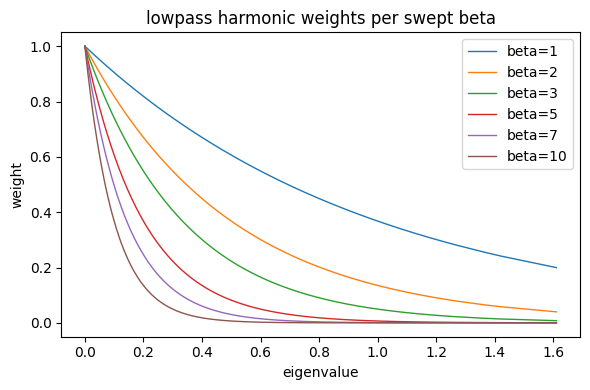

In [2]:
betas = [1, 2, 3, 5, 7, 10]

fig, ax = plt.subplots(figsize=(6, 4))
for beta in betas:
    w = compute_harmonic_prior(eigval, relaxation=beta, method="lowpass")
    ax.plot(eigval, w, lw=1, label=f"beta={beta}")
ax.set_xlabel("eigenvalue")
ax.set_ylabel("weight")
ax.set_title("lowpass harmonic weights per swept beta")
ax.legend()
fig.tight_layout()

## 🎯 - Solve and evaluate across runs x betas

For each of `runs` x `betas`: solve with `wCSET` (`harmonic_method="lowpass"`), then score
against that run's own `gold`: spatial correlation over the whole cropped window, average
precision (precision-recall curve, at half-rising-phase and peak-phase, same construction
as `inverse-simf.ipynb`), and peak-localization-error at half-rising-phase only (per this
round's scope). Registered into `metrics` under `label=f"beta={beta}"`, so the 10 runs at
a given beta become repeats `MetricSuite` auto-aggregates into a mean +/- CI when plotted.

`sLORETA` is solved once per run too (no `beta` -- connectome-free) and registered under
`label="sloreta"`, as a reference point external to the whole gap/lowpass/gap-spectrum
weighting question.

In [3]:
metrics = mm.metric.MetricSuite(f"Harmonic Prior Tuning {sub} lowpass sweep")
scalar_rows = []

for run in tqdm(runs, desc="runs"):
    ave = dm.load(sub, "ave", run=run)
    ncov = dm.load(sub, "cov", run=run)
    gold = dm.load(sub, "gold", run=run)

    data = ave.copy().crop(tmin=tmin, tmax=tmax)
    ground = gold.copy().crop(tmin=tmin, tmax=tmax)

    snr, snr_db = mm.analysis.eeg.estimate_evoked_snr(evoked=ave, baseline=(-0.4, -0.2), noise_cov=ncov)
    lambda2 = max(0.01, 1.0 / (snr.max()**2))

    hrp = mm.analysis.eeg.get_rising_phase(data, ratio=0.5, as_idx=True)[0]
    pp = mm.analysis.eeg.get_rising_phase(data, ratio=1, as_idx=True)[0]

    src_seed = dm.load(sub, "source", run=run)
    true_source_mask = src_seed.select_targets(simulator.hm.src, simulator.hm.parc, simulator.hm.ras2tkras)

    def evaluate_and_register(label, sol):
        # spatial correlation over the whole cropped window
        corr = np.asarray(mm.analysis.inverse.compute_stc_correlation(ground, sol, mode="spatial", method="pearson"))
        metrics.register(label, "correlation", corr, times=ground.times)

        # average precision at half-rising-phase / peak-phase. Each run is a
        # different source location (not a noise-repeat of the same one), so
        # raw curves land on different, non-aligned recall grids -- resample
        # onto a shared grid before registering, or aggregating 10 runs'
        # curves produces exactly the noisy/blocky plot this replaces (see
        # resample_pr_curve's own docstring: "makes curves from different
        # runs impossible to average directly"). AP itself is still taken
        # from the raw (un-resampled) curve -- it's already an exact
        # integral, resampling would only add interpolation error to it.
        pr_hrp = mm.core.calc_pr_curve(ground.data[:, hrp] > 0, sol.data[:, hrp])
        precision_hrp_grid, recall_grid = mm.core.resample_pr_curve(pr_hrp["precision"], pr_hrp["recall"])
        metrics.register(label, "precision_hrp", precision_hrp_grid, recall=recall_grid)

        pr_pp = mm.core.calc_pr_curve(ground.data[:, pp] > 0, sol.data[:, pp])
        precision_pp_grid, recall_pp_grid = mm.core.resample_pr_curve(pr_pp["precision"], pr_pp["recall"])
        metrics.register(label, "precision_pp", precision_pp_grid, recall=recall_pp_grid)

        # peak localization error at half-rising-phase only, this round
        hit_hrp = find_peak_localization_error(sol.data[:, hrp], true_source_mask, dipole_positions)
        metrics.register(label, "localization_error_hrp", hit_hrp["distance_mm"])

        return pr_hrp["ap"], pr_pp["ap"], hit_hrp["distance_mm"]

    for beta in betas:
        inv = mm.analysis.inverse.wCSET(
            forward = fwd,
            noise_cov = ncov,
            depth = 0.5,
            eigenvectors = eigvec,
            eigenvalues = eigval,
            harm = beta,
            harmonic_method = "lowpass",
        )
        sol = inv.solve(data, lambda2)
        ap_hrp, ap_pp, loc_err_hrp = evaluate_and_register(f"beta={beta}", sol)
        scalar_rows.append(dict(run=run, method="lowpass", beta=beta, ap_hrp=ap_hrp, ap_pp=ap_pp, loc_err_hrp=loc_err_hrp))

    # sLORETA reference: no beta, no connectome -- an external baseline for
    # the whole gap/lowpass/gap-spectrum weighting question, not a variant of it.
    inv_sloreta = mne.minimum_norm.make_inverse_operator(
        info = data.info,
        forward = fwd,
        noise_cov = ncov,
        fixed = True,
        depth = None,
    )
    sol_sloreta = mne.minimum_norm.apply_inverse(data, inv_sloreta, lambda2, method="sLORETA")
    ap_hrp, ap_pp, loc_err_hrp = evaluate_and_register("sloreta", sol_sloreta)
    scalar_rows.append(dict(run=run, method="sloreta", beta=np.nan, ap_hrp=ap_hrp, ap_pp=ap_pp, loc_err_hrp=loc_err_hrp))

scalar_df = pd.DataFrame(scalar_rows)

runs:   0%|          | 0/10 [00:00<?, ?it/s]

    Created an SSP operator (subspace dimension = 1)


Computing rank from covariance with rank=None


    Using tolerance 4e-15 (2.2e-16 eps * 203 dim * 0.088  max singular value)


    Estimated rank (eeg): 202


    EEG: rank 202 computed from 203 data channels with 1 projector


... (402 outputs left out)

    sLORETA...


[done]


runs: 100%|██████████| 10/10 [02:36<00:00, 13.18s/it]

runs: 100%|██████████| 10/10 [02:36<00:00, 15.69s/it]

## 📊 - Visualization

Correlation vs. time, localization error at hrp, and precision-recall at hrp/pp -- one
colored line/box per `beta`, mean +/- CI across the 10 runs.

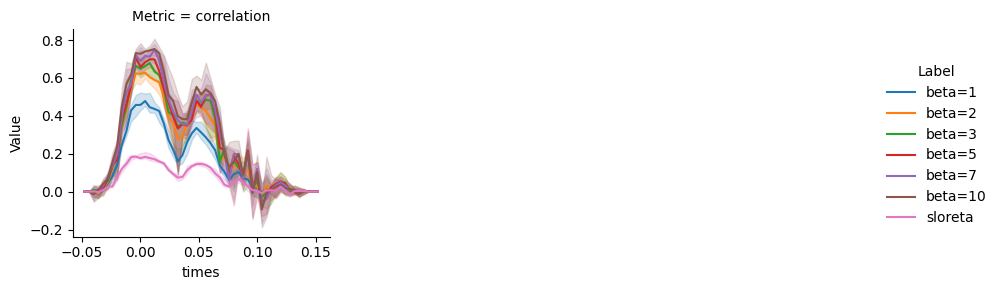

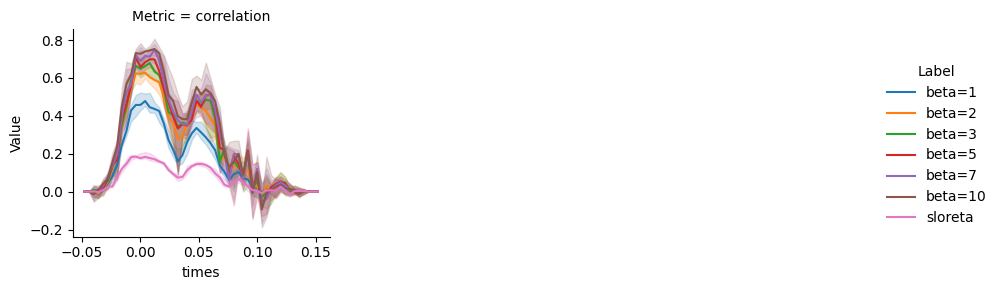

In [4]:
# median +/- IQR across the 10 runs, same convention Sipes et al. 2024 use for
# their inter-subject plots -- more robust than mean+-SD here since the 10
# runs are different source locations (real heterogeneity), not noise
# repeats of one signal, so one easy/hard run shouldn't dominate the summary.
metrics.plot(
    metrics = ["correlation"],
    coord = "times",
    kind = "line",
    estimator = "median",
    errorbar = ("pi", 50),
)

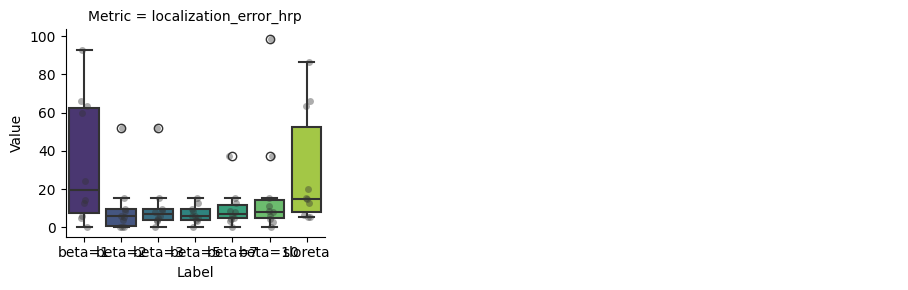

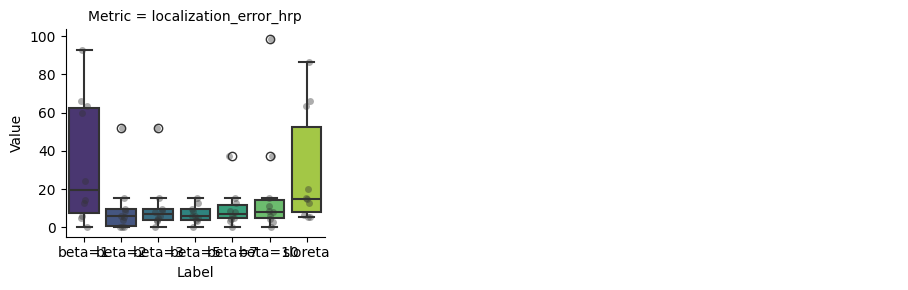

In [5]:
metrics.plot(
    metrics = ["localization_error_hrp"],
    kind = "box",
)

AP by method/beta (mean +/- std across runs 1-10):


ap_hrp               ap_pp           loc_err_hrp           
                  mean       std      mean       std        mean        std
method  beta                                                               
lowpass 1.0   0.380354  0.073399  0.743190  0.103786   34.434196  32.847769
        2.0   0.442929  0.083678  0.764119  0.097806   10.091289  15.515146
        3.0   0.432479  0.109018  0.771881  0.101071   11.145644  14.941142
        5.0   0.419387  0.130744  0.796800  0.106200    7.000019   4.589580
        7.0   0.422374  0.143634  0.825769  0.098068   10.036699  10.526691
        10.0  0.436067  0.142624  0.850925  0.086782   19.214076  29.776984
sloreta NaN   0.348898  0.065475  0.730147  0.100044   29.594661  30.243451

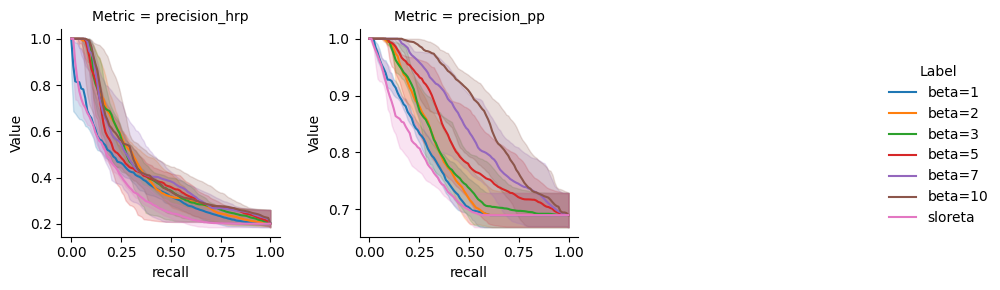

In [6]:
metrics.plot(
    metrics = ["precision_hrp", "precision_pp"],
    coord = "recall",
    kind = "line",
    estimator = "median",
    errorbar = ("pi", 50),
)

print("AP by method/beta (mean +/- std across runs 1-10):")
scalar_df.groupby(["method", "beta"], dropna=False)[["ap_hrp", "ap_pp", "loc_err_hrp"]].agg(["mean", "std"])